# 1. Gaussove eliminacije  i LU rastav 

Implementacija funkcije koja računa $LU$ rastav matrice A

In [4]:
import numpy as np
def LU_dekompozicija(A):
    n=len(A)
    for k in range(0,n-1):
        for i in range(k+1,n):
            if A[i,k]!=0.0:
                A[i,k]=A[i,k]/(A[k,k]) #multiplikator 
                A[i, k+1:n]=A[i, k+1:n]-A[i,k]*A[k, k+1:n]
    return A
    

Funkciju ćemo primijeniti na matrici $$\begin{bmatrix} 2& 1& 0\\ 4& 4& 5\\ 6& 7& 8\end{bmatrix}$$
Kao izlaz dobivamo matricu čiji gornji trokut je matrica $U$ a elementi ispod glavne dijagonale su elementi matrice $L$

In [5]:
A=np.array([[2.0, 1.0, 3.0 ],[4.0, 4.0, 5.0], [6.0, 7.0, 8.0]])
B=LU_dekompozicija(A)
print(B)

[[ 2.  1.  3.]
 [ 2.  2. -1.]
 [ 3.  2.  1.]]


Matricu $L$ možemo dobiti preko funkcije np.tril (proučiti kako ova funkcija radi), a matricu $U$ pomoću **np.triu(ulazna matrica, id dijagonale)**

Funkcija *tril(ulazna matrica, identifikator dijagonale )* vraća matricu koja uzima donji dio ulazne matrice ispod(i uključujući) dijagonalu s time da glavna dijagonala ima identfikator 1, dijagonala iznad nje 1 i dijagonala ispod -1 itd. Slično je sa funkcijom *triu(ulazna matrica, id dijagonale)*

In [6]:
L=np.tril(A,-1)+np.identity(3)
print(L)

[[1. 0. 0.]
 [2. 1. 0.]
 [3. 2. 1.]]


In [7]:
U=np.triu(A,0)
print(U)

[[ 2.  1.  3.]
 [ 0.  2. -1.]
 [ 0.  0.  1.]]


Rješavanje sustava Ly=b (supstitucije unaprijed). u donjem kodu  funkcija np.dot(x,y) predstavja skalarni produkt vektora. (Dijagonalni elementi od $L$ su 1 pa nije ni potrebni dijeliti s dijagonalnim elementima u donjem kodu)

In [8]:
def forward(L,b):
# supstitucija unaprijed
    b[0] = b[0] / L[0, 0]
    n=len(L)
    for i in range(1, n):
        b[i] = (b[i] - np.dot(L[i,:i], b[:i])) / L[i,i]
    return b

In [10]:
b=np.array([[-1],[-1],[-2]])

In [11]:
y=forward(L,b)
print(y)


[[-1]
 [ 1]
 [-1]]


Rješavanje sustava $Ux=y$ odnosno povratne supstitucije

In [12]:
def backward(U,b):
# supstitucija unatrag
    n=len(U)
    for k in range(n-1,-1,-1):
        b[k] = (b[k] - np.dot(U[k,k+1:n],b[k+1:n]))/U[k,k]
    return b

In [13]:
x=backward(U,y)
print(x)

[[ 1]
 [ 0]
 [-1]]


## 2. Kako nastaje linearan sustav. Primjer trodijagonalnog sustava. Thomasov algoritam

U ovom dijelu predavanja prikazat ćemo kako nastaje jedan trodijagonalni linearan sustav iz diskretizacije diferencijalne jednadžbe.


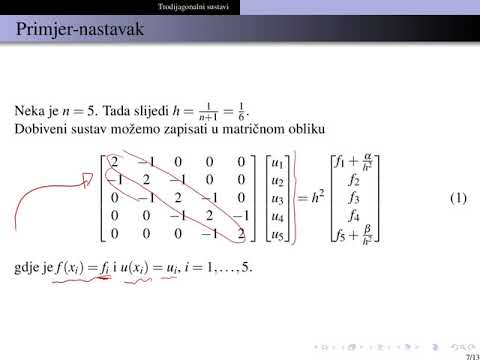

In [14]:
from IPython.lib.display import YouTubeVideo
vid = YouTubeVideo("9vwZLHGMMGg")
display(vid)

**Napomena** U gornjem videu na str6. za $i=5$ je pogreška (ne treba lijevu stranu množiti s $\frac{1}{h^2}$ jer je već faktor $h^2$ već na desnoj strani)

**Zadatak** Razmislite o implementaciji Thomasovog algoritma iz prethodnog video predavanja kojeg primijenjujemo za rješavanje diferencijelne jednadžbe i po volji odabranu desnu stranu! Također svoje rješenje prikažite grafički i usporedite s točnim rješenjem! Ovdje će implementacija biti dodana do početka sljedećeg predavanja!

## Implementacija Thomasovog algoritma i numeričko rješavanje rubnog problema

Trodijagonalnu matricu
$$A=\begin{bmatrix} b_0 & c_0 & & & \\ a_0 & b_1 & c_1 & & \\ & \ddots & \ddots & \ddots & \\ & & a_{n-3} & b_{n-2} & c_{n-2}\\ & & & a_{n-2} & b_{n-1}\end{bmatrix}$$
pamtimo pomoću tri vektora $a=[a_0,\dots,a_{n-2}]$, $b=[b_0,\dots,b_{n-1}]$ i $c=[c_0,\dots,c_{n-2}]$, dakle umjesto $n^2$ elemenata pamtimo samo $3n-2$.

### Thomasov algoritam

Gaussova eliminacija bez pivotiranja na trodijagonalnoj matrici daje faktorizaciju $A=LU$. Matrica $L$ ima jedinice na dijagonali i multiplikatore $l_k$ ispod nje, a $U$ ima dijagonalu $u_k$ i istu gornju sporednu dijagonalu $c_k$ kao $A$:
$$u_0=b_0,\qquad l_k=\frac{a_{k-1}}{u_{k-1}},\qquad u_k=b_k-l_k\,c_{k-1},\qquad k=1,\dots,n-1.$$
Sustav $Ax=f$ zatim rješavamo u dva koraka, $Ly=f$ i $Ux=y$:
$$y_0=f_0,\quad y_k=f_k-l_k\,y_{k-1};\qquad x_{n-1}=\frac{y_{n-1}}{u_{n-1}},\quad x_k=\frac{y_k-c_k\,x_{k+1}}{u_k}.$$
Ukupno je to oko $8n$ računskih operacija, tj. složenost $O(n)$, za razliku od $O(n^3)$ za punu matricu.

**Stabilnost.** Algoritam ne pivotira, pa može pasti (pivot $u_k=0$) ili biti nestabilan zbog malog pivota (vidi zadatak 5 iz 1. laboratorijske vježbe). Stabilan je ako je matrica strogo dijagonalno dominantna, $|b_k|>|a_{k-1}|+|c_k|$, ili simetrična pozitivno definitna. Matrica rubnog problema koji rješavamo u nastavku je simetrična pozitivno definitna, pa pivotiranje nije potrebno.

In [15]:
def LUdecomptridiagonal(a,b,c):
    n=len(b)
    for k in range(1,n):
        mu=a[k-1]/b[k-1]
        b[k]=b[k]-mu*c[k-1]
        a[k-1]=mu
    return a,b,c

def LUsolvetridiagonal(a,b,c,f):
    n=len(b)
    for k in range(1,n):
        f[k]=f[k]-a[k-1]*f[k-1]
    f[n-1]=f[n-1]/b[n-1]
    for k in range(n-2,-1,-1):
        f[k]=(f[k]-c[k]*f[k+1])/b[k]
    return f

**Napomene uz implementaciju.**

- U kodu je multiplikator $l_k$ spremljen u `a[k-1]`, a pivot $u_k$ u `b[k]`. Petlja u `LUdecomptridiagonal` je doslovno formula $l_k=\frac{a_{k-1}}{u_{k-1}}$, $u_k=b_k-l_k\,c_{k-1}$.
- Funkcije rade **na mjestu** (*in place*): `LUdecomptridiagonal` prepisuje vektor `a` multiplikatorima $l_k$, a vektor `b` dijagonalom $u_k$ matrice $U$. Vektor `c` se ne mijenja, jer je gornja sporedna dijagonala od $U$ jednaka onoj od $A$. Faktorizacija tako ne treba dodatnu memoriju.
- `LUsolvetridiagonal` prepisuje vektor `f`: najprije rješenjem $y$ sustava $Ly=f$, a zatim rješenjem $x$ sustava $Ux=y$, koje i vraća.
- Posljedica: nakon poziva originalni `a`, `b` i `f` više nisu dostupni. Ako ih trebamo i kasnije (npr. za usporedbu ili provjeru reziduala), funkcijama predajemo kopije (`a.copy()` itd.).
- Vektori moraju biti realnog tipa (`float`); u cjelobrojnom nizu rezultati dijeljenja bi se odsijecali.

### Rubni problem

Rješavamo
$$-u''(x)=f(x),\quad x\in(0,1),\qquad u(0)=\alpha,\quad u(1)=\beta.$$
Na mreži $x_i=ih$, $i=0,\dots,n+1$, $h=\frac{1}{n+1}$, drugu derivaciju zamijenimo centralnom razlikom
$$u''(x_i)\approx\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}.$$
Za unutarnje čvorove $i=1,\dots,n$ dobivamo jednadžbe
$$-u_{i-1}+2u_i-u_{i+1}=h^2 f(x_i),$$
uz $u_0=\alpha$ i $u_{n+1}=\beta$. Poznate rubne vrijednosti prebacimo na desnu stranu, pa dobivamo trodijagonalni sustav
$$\begin{bmatrix}2&-1&&\\-1&2&\ddots&\\&\ddots&\ddots&-1\\&&-1&2\end{bmatrix}\begin{bmatrix}u_1\\u_2\\\vdots\\u_n\end{bmatrix}=\begin{bmatrix}h^2f(x_1)+\alpha\\h^2f(x_2)\\\vdots\\h^2f(x_n)+\beta\end{bmatrix}.$$
Desna strana je pomnožena s $h^2$, pa matrica nema faktor $1/h^2$.

U primjeru je $f(x)=16\pi^2\sin(4\pi x)$ i $\alpha=\beta=0$, a egzaktno rješenje je $u(x)=\sin(4\pi x)$.

In [16]:
def set_abcf(x, alpha, beta, rhs):
    """Trodijagonalni sustav za -u'' = rhs(x) na mreži x, uz u(x_0)=alpha, u(x_{n+1})=beta.

    x je ekvidistantna mreža s n+2 točke (uključujući rubove).
    """
    n = len(x) - 2                        # broj unutarnjih čvorova
    h = x[1] - x[0]
    a = -np.ones(n-1)
    b = 2.0 * np.ones(n)
    c = -np.ones(n-1)
    f = h**2 * rhs(x[1:-1])
    f[0] += alpha                         # rubni uvjeti prelaze na desnu stranu
    f[-1] += beta
    return a, b, c, f


def rhs(x):
    return 16.0 * np.pi**2 * np.sin(4.0 * np.pi * x)


def exact_solution(x):
    return np.sin(4.0 * np.pi * x)


def solve_bvp(n, alpha=0.0, beta=0.0, rhs=rhs):
    """Vraća mrežu (s rubovima) i numeričko rješenje u svim čvorovima."""
    x = np.linspace(0.0, 1.0, n+2)
    a, b, c, f = set_abcf(x, alpha, beta, rhs)   # novi vektori pri svakom pozivu
    a, b, c = LUdecomptridiagonal(a, b, c)          # a, b se prepisuju faktorizacijom
    u_inner = LUsolvetridiagonal(a, b, c, f)        # f se prepisuje rješenjem
    return x, np.r_[alpha, u_inner, beta] # sopajanje  1 vektor (dodamo rubove)

Sada uvodimo biblioteku za crtanje i crtamo graf dobivenom rješenja. Uspoređijemo ga s egzaktnim rješenjem.

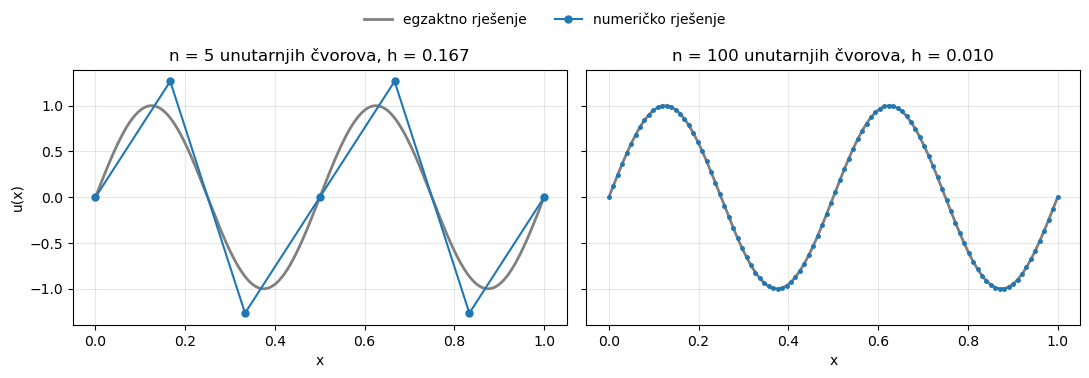

In [17]:
import matplotlib.pyplot as plt
z = np.linspace(0, 1, 1000)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, n in zip(axes, [5, 100]):
    x, u = solve_bvp(n)
    ax.plot(z, exact_solution(z), color="gray", lw=2, label="egzaktno rješenje")
    ax.plot(x, u, "o-" if n < 20 else ".", ms=5, label="numeričko rješenje")
    ax.set_title(f"n = {n} unutarnjih čvorova, h = {1/(n+1):.3f}")
    ax.set_xlabel("x")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("u(x)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()